# Analyse: Wirtschaft, Handel und Militär 1950–2014

Vier Haupthypothesen (H1–H4), Fokus auf **H1: Produktivität und Militärpersonal**.

Das Projekt ist in vier Schritte geteilt. Dieses Notebook ist **Schritt 2**; die anderen Schritte stecken im Ordner `projekt/` und werden hier nur aufgerufen.

| Schritt | Datei | Was passiert |
|---|---|---|
| 1 Aufbereitung | `projekt/aufbereitung.py` | 10 Originaldateien bereinigen, zusammenführen, je Hypothese eine fertige Tabelle bilden |
| **2 Analyse** | **dieses Notebook** | Korrelationen, Ausreißer, Ebenen, Gruppen, einzelne Länder |
| 3 Grafiken | `projekt/grafiken.py` | alle Diagramme (Abschnitt 6) |
| 4 Bericht | `projekt/bericht.py` | vollständiger Excel-Bericht mit allen explorativen Tabellen (Abschnitt 7, optional) |

Einstellungen wie Zeitraum, Schwellen und die Hypothesen selbst stehen in `projekt/einstellungen.py`.

In [1]:
import pandas as pd
from projekt import aufbereitung, statistik, grafiken
from projekt.einstellungen import HYPOTHESEN, MAIN

pd.options.display.float_format = '{:.4g}'.format

## 1 Daten laden

Schritt 1 liefert für jede Hypothese eine fertige Tabelle **vollständiger Wertepaare**. Jede Tabelle hat dieselben Spalten:
`x` und `y` (die beiden Variablen), Land und Jahr, Kontinent und Kriegsstatus.
Deshalb funktioniert die Analyse unten für jede Hypothese gleich.

Schritt 1 läuft beim Laden einmal komplett durch (etwa 15 Sekunden); die Originaldateien in `Data/` werden dabei nicht verändert.

In [2]:
daten = aufbereitung.lade()
S = daten.stichproben          # S['H1'] ist die fertige Tabelle für H1

pd.DataFrame({name: {'Frage': h.titel, 'x': h.x, 'y': h.y, 'erwartet': h.erwartet,
                     'Einheit': h.einheit, 'n': len(S[name])}
              for name, h in HYPOTHESEN.items()}).T

1  Originaldaten einlesen …


2  Messwerte bereinigen
3  Länder zuordnen


4  SIPRI-Militärausgaben
5  Länderjahre
6  Importstruktur


7  Länderpaare


8  Exportentfernung


9  Hypothesentabellen und Prüfung


10 Analysestichproben


11 Kriegs- und Kontinentkontext
12 Kontext anhängen


,Frage,x,y,erwartet,Einheit,n
H1,Produktivität und Militärpersonal,productivity,military_per_1000,negative,Länderjahr,7708
H2,Importkonzentration und Militärpersonal,import_hhi_observed,military_per_1000,positive,Länderjahr,5704
H3,Handelsverflechtung und Militärausgabenwachstum,mutual_import_share,military_growth_gap_pp,negative,Länderpaar-Jahr,176593
H4,Wohlstandsunterschied und Handel,wealth_gap_log,mutual_import_share,negative,Länderpaar-Jahr,259503
H8,Exportdistanz und späteres Wachstum,export_distance_observed_km,growth_next_5y_pct,positive,Länderjahr,2987
E1,Bevölkerung und Importkonzentration,tpop,import_hhi_observed,negative,Länderjahr,5704
E2,Urbanisierung und Militärpersonal,urban_share,military_per_1000,negative,Länderjahr,9182
E3,Wirtschaftsgröße und absolute Asymmetrie,total_gdp_gap_log,asymmetry_abs,positive,Länderpaar-Jahr,259503
E4,Wirtschaftsgröße und relative Asymmetrie,total_gdp_gap_log,asymmetry_relative,positive,Länderpaar-Jahr,217405
E5,Entfernung und Handel,log_distance,mutual_import_share,negative,Länderpaar-Jahr,259503


## 2 Ergebnisse auf einen Blick

Kursvorgaben: 3–5 Hypothesen, mindestens 5.000 Wertepaare, n, r und p angeben.
Einordnung von r: über 0,5 stark, über 0,3 moderat, über 0,1 schwach, darunter nicht interpretieren.

In [3]:
ergebnisse = pd.DataFrame({name: statistik.korrelation(S[name]) for name in MAIN}).T
ergebnisse['erwartet'] = [HYPOTHESEN[name].erwartet for name in MAIN]
ergebnisse

,n,r,p,rho,Stärke,erwartet
H1,7708,0.2401,1.795e-101,0.3015,schwach,negative
H2,5704,-0.1242,4.581e-21,-0.2307,schwach,positive
H3,176593,-0.03326,2.101e-44,-0.1827,nicht interpretierbar,negative
H4,259503,-0.01782,1.077e-19,-0.01748,nicht interpretierbar,negative


## 3 H1 im Detail: Produktivität und Militärpersonal

**Erwartung:** Je produktiver eine Wirtschaft (BIP je Erwerbstätigem), desto weniger Soldaten je 1.000 Einwohner.

### 3.1 Das Ergebnis

In [4]:
h1 = S['H1']
pd.DataFrame({'H1': statistik.korrelation(h1)}).T

,n,r,p,rho,Stärke
H1,7708,0.2401,1.795e-101,0.3015,schwach


### 3.2 Liegt es an Ausreißern?

Drei Prüfungen: die extremsten 1 % weglassen (trimmen), extreme Werte auf die Grenze setzen (winsorisieren) und jeweils ein ganzes Land weglassen.

In [5]:
pd.DataFrame({'vollständig': statistik.korrelation(h1),
              'getrimmt (1.–99. Perzentil)': statistik.korrelation(statistik.trimmen(h1)),
              'winsorisiert': statistik.korrelation(statistik.winsorisieren(h1))}).T

,n,r,p,rho,Stärke
vollständig,7708,0.2401,1.795e-101,0.3015,schwach
getrimmt (1.–99. Perzentil),7482,0.1833,1.44e-57,0.2897,schwach
winsorisiert,7708,0.2361,3.962e-98,0.3015,schwach


In [6]:
statistik.ohne_jedes_land(h1).head(5)

,Land,Zeilen weg,r ohne Land,Änderung
0,ARE,44,0.1616,-0.07844
1,TWN,64,0.2665,0.02644
2,BRN,31,0.2248,-0.0153
3,SYR,54,0.255,0.01495
4,QAT,44,0.2277,-0.01234


### 3.3 Kernbefund: zwischen Ländern und innerhalb der Länder

- **Zwischen Ländern:** ein Punkt je Land, sein Durchschnitt über alle Jahre.
- **Innerhalb der Länder:** jedes Jahr als Abweichung vom eigenen Durchschnitt.
- **Fixed Effects:** Regression mit Länder- und Jahreseffekten (Produktivität logarithmiert), Standardfehler nach Land und Jahr geclustert.

In [7]:
pd.DataFrame({'alle Länderjahre': statistik.korrelation(h1),
              'zwischen Ländern': statistik.zwischen(h1),
              'innerhalb der Länder': statistik.innerhalb(h1)}).T

,n,r,p,rho,Stärke
alle Länderjahre,7708,0.2401,1.795e-101,0.3015,schwach
zwischen Ländern,172,0.3956,NaN,0.3987,moderat
innerhalb der Länder,7708,-0.1649,NaN,-0.337,schwach


In [8]:
pd.Series(statistik.fixed_effects(h1), name='H1 mit Länder- und Jahreseffekten')

beta             -1.416
95% unten        -3.165
95% oben         0.3334
p (geclustert)   0.1108
n                  7708
Länder              172
Jahre                65
Name: H1 mit Länder- und Jahreseffekten, dtype: float64

### 3.4 Kontinente

In [9]:
statistik.nach_gruppen(h1, 'continent')

,continent,n,r,p,rho,Stärke
0,Afrika,2137,0.1943,1.285e-19,0.3475,schwach
1,Asien,1906,0.2682,9.033e-33,0.4055,schwach
2,Europa,1788,-0.4262,7.64e-80,-0.4623,moderat
3,Nordamerika,971,0.1444,6.293e-06,0.02304,schwach
4,Ozeanien,165,-0.6603,5.023e-22,-0.655,stark
5,Südamerika,723,-0.0899,0.0156,-0.1357,nicht interpretierbar
6,Unbekannt,18,-0.8238,2.647e-05,-0.1714,stark


### 3.5 Einzelne Länder

Ein einziges Land kann das Vorzeichen einer Region drehen. Und jedes Land für sich kann negativ sein, obwohl alle zusammen positiv sind.

In [10]:
nordamerika = h1[h1.continent == 'Nordamerika']
pd.DataFrame({'Nordamerika': statistik.korrelation(nordamerika),
              'Nordamerika ohne USA': statistik.korrelation(nordamerika[nordamerika.iso3 != 'USA'])}).T

,n,r,p,rho,Stärke
Nordamerika,971,0.1444,6.293e-06,0.02304,schwach
Nordamerika ohne USA,906,-0.1065,0.001324,-0.153,schwach


In [11]:
laender = ['USA', 'DEU', 'JPN']
tabelle = {iso: statistik.korrelation(h1[h1.iso3 == iso]) for iso in laender}
tabelle['alle drei zusammen'] = statistik.korrelation(h1[h1.iso3.isin(laender)])
pd.DataFrame(tabelle).T

,n,r,p,rho,Stärke
USA,65,-0.87,5.142e-21,-0.9435,stark
DEU,24,-0.9028,1.602e-09,-0.8748,stark
JPN,63,-0.58,6.304e-07,-0.6653,stark
alle drei zusammen,152,0.007677,0.9252,0.1086,nicht interpretierbar


### 3.6 Kriegsstatus

COW erfasst zwischenstaatliche Kriege bis 2007. „Keine Beteiligung erfasst“ heißt nicht Frieden (Bürgerkriege fehlen).

In [12]:
statistik.nach_gruppen(h1, 'war_group')

,war_group,n,r,p,rho,Stärke
0,Beteiligung erfasst,211,0.03725,0.5906,0.1936,nicht interpretierbar
1,Keine Beteiligung erfasst,6350,0.2879,1.99e-121,0.3287,schwach
2,Status unbekannt,1147,0.3414,1.055e-32,0.4239,moderat


In [13]:
ohne_kriegslaender = statistik.waehle_stichprobe(h1, ausschluss='above_mean_share')
pd.DataFrame({'alle Länderjahre': statistik.korrelation(h1),
              'ohne Länder mit überdurchschnittlich vielen Kriegsjahren': statistik.korrelation(ohne_kriegslaender)}).T

,n,r,p,rho,Stärke
alle Länderjahre,7708,0.2401,1.795e-101,0.3015,schwach
ohne Länder mit überdurchschnittlich vielen Kriegsjahren,4530,0.2194,1.665e-50,0.2815,schwach


## 4 Die anderen Hypothesen: dieselben zwei Lehren

**Lehre 1, die Ebene (H2):** Der Zusammenhang besteht zwischen Ländern, nicht innerhalb.

In [14]:
h2 = S['H2']
pd.DataFrame({'alle Länderjahre': statistik.korrelation(h2),
              'zwischen Ländern': statistik.zwischen(h2),
              'innerhalb der Länder': statistik.innerhalb(h2)}).T

,n,r,p,rho,Stärke
alle Länderjahre,5704,-0.1242,4.581e-21,-0.2307,schwach
zwischen Ländern,170,-0.1673,NaN,-0.3035,schwach
innerhalb der Länder,5704,-0.01452,NaN,0.08277,nicht interpretierbar


**Lehre 2, einzelne Länder (H3, H4):** Angola 1993 bei H3, die USA bei H4.

In [15]:
h3 = S['H3']
pd.DataFrame({'alle Paare': statistik.korrelation(h3),
              'ohne Angola': statistik.korrelation(statistik.waehle_stichprobe(h3, landerliste=['AGO']))}).T

,n,r,p,rho,Stärke
alle Paare,176593,-0.03326,2.101e-44,-0.1827,nicht interpretierbar
ohne Angola,174093,-0.05977,1.618e-137,-0.1811,nicht interpretierbar


In [16]:
h4 = S['H4']
amerika = h4[h4.continent_pair == 'Nordamerika / Südamerika']
pd.DataFrame({'alle Paare': statistik.korrelation(h4),
              'Nord-/Südamerika': statistik.korrelation(amerika),
              'Nord-/Südamerika ohne USA': statistik.korrelation(statistik.waehle_stichprobe(amerika, landerliste=['USA']))}).T

,n,r,p,rho,Stärke
alle Paare,259503,-0.01782,1.077e-19,-0.01748,nicht interpretierbar
Nord-/Südamerika,7388,0.3349,4.8e-193,0.2067,moderat
Nord-/Südamerika ohne USA,6928,0.03329,0.005588,0.07218,nicht interpretierbar


## 5 Nebenfragen

Nach den ersten Ergebnissen ergänzt, um Erklärungen zu suchen (explorativ). H8 liegt unter 5.000 Wertepaaren.

In [17]:
pd.DataFrame({name: {'Frage': HYPOTHESEN[name].titel, **statistik.korrelation(S[name])}
              for name in ['E1', 'E2', 'E3', 'E4', 'E5', 'H8']}).T

,Frage,n,r,p,rho,Stärke
E1,Bevölkerung und Importkonzentration,5704,-0.1395,3.355e-26,-0.3139,schwach
E2,Urbanisierung und Militärpersonal,9182,0.3042,6.887e-196,0.4388,moderat
E3,Wirtschaftsgröße und absolute Asymmetrie,259503,0.2164,0,0.231,schwach
E4,Wirtschaftsgröße und relative Asymmetrie,217405,0.3389,0,0.3031,moderat
E5,Entfernung und Handel,259503,-0.2425,0,-0.2635,schwach
H8,Exportdistanz und späteres Wachstum,2987,-0.03447,0.05963,-0.05783,nicht interpretierbar


## 6 Grafiken

Alle Diagramme kommen aus `projekt/grafiken.py`; hier wird jedes mit einer Zeile aufgerufen.

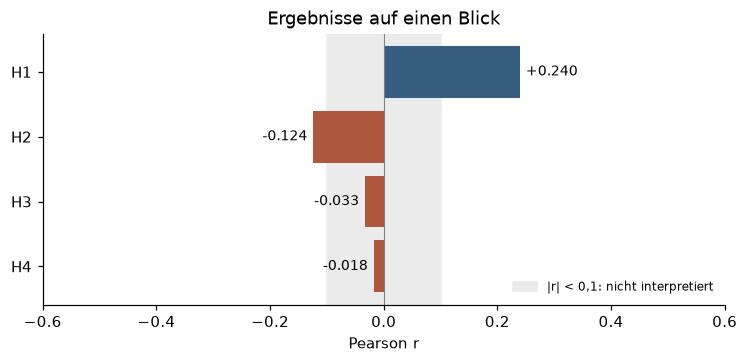

In [18]:
grafiken.ergebnisse(ergebnisse);

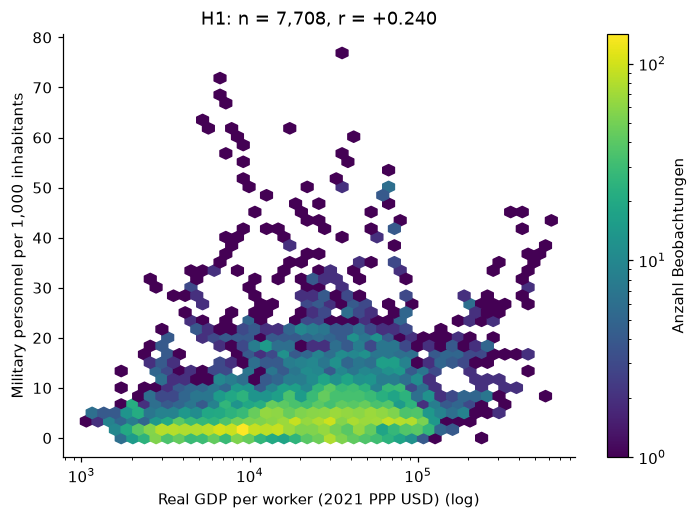

In [19]:
grafiken.streudiagramm(h1, 'H1');

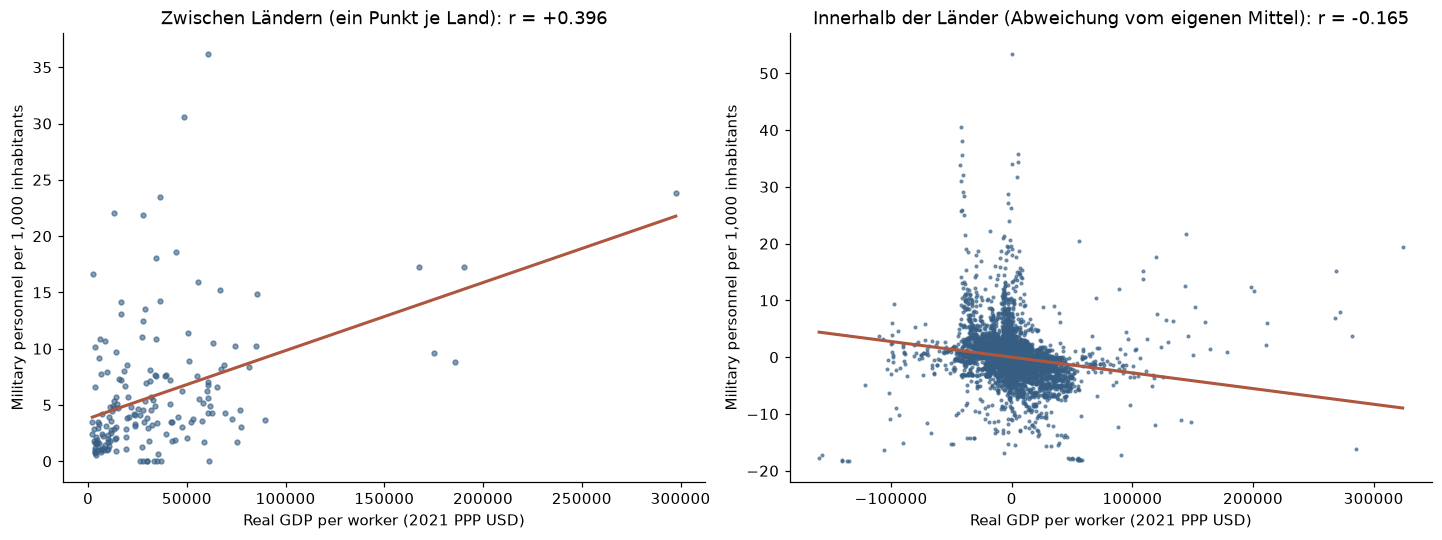

In [20]:
grafiken.zwischen_innerhalb(h1, 'H1');

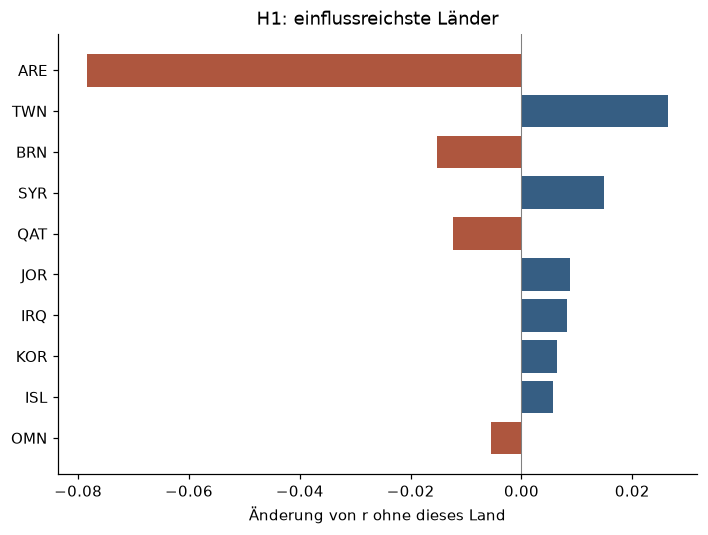

In [21]:
grafiken.laendereinfluss(h1, 'H1');

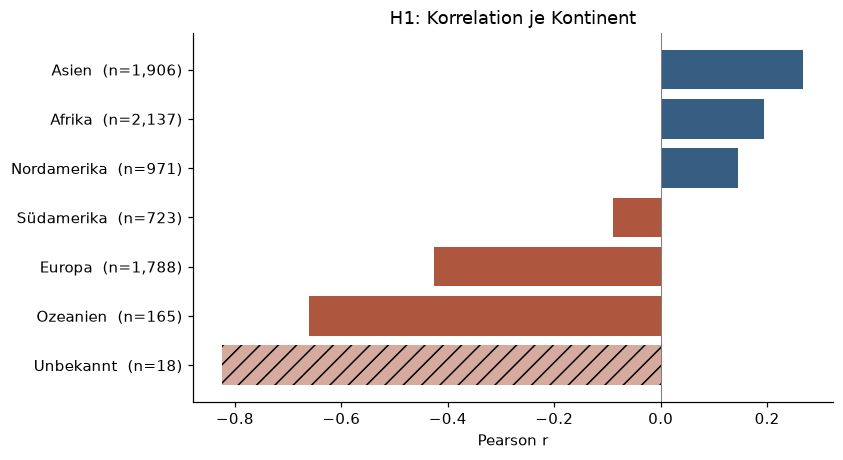

In [22]:
grafiken.nach_gruppen(statistik.nach_gruppen(h1, 'continent'), 'continent', 'H1: Korrelation je Kontinent');

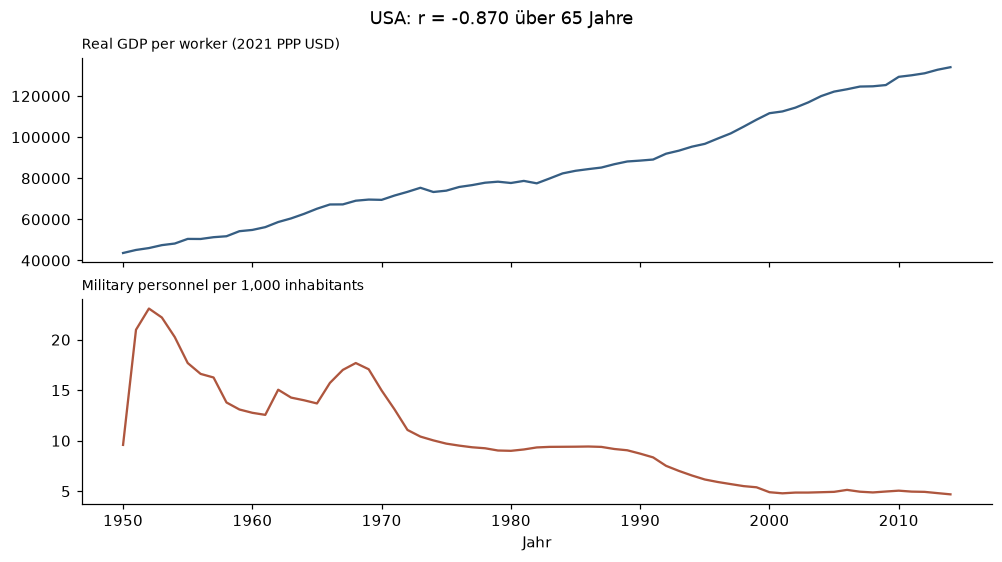

In [23]:
grafiken.land_im_zeitverlauf(h1, 'USA', 'H1');

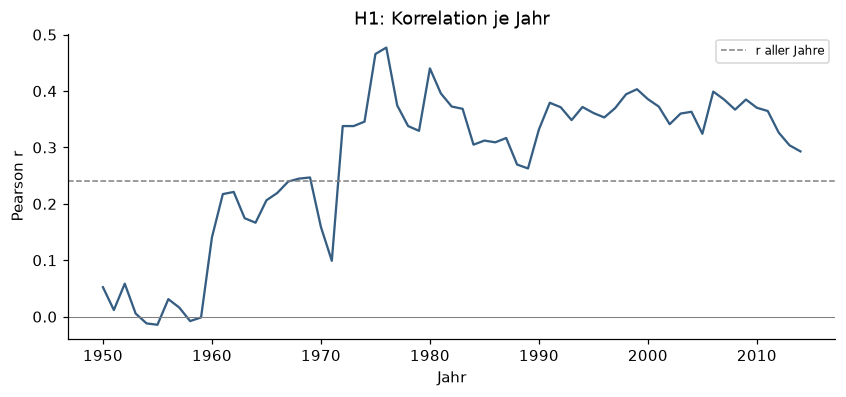

In [24]:
grafiken.zeitverlauf(h1, 'H1');

## 7 Vollständiger Excel-Bericht (optional)

Schritt 4 rechnet zusätzlich alle explorativen Tabellen (Sensitivitäten, Einflussdiagnosen, Gruppen, Zusatzmodelle) und schreibt sie mit rund 170 Grafiken in eine Excel-Datei unter `Ergebnisse/`. Dauert etwa zwei Minuten.

In [25]:
# from projekt import bericht
# bericht.erstelle(daten)